# Sección 1 Descarga del dataset

En esta sección se guardo el dataset en un drive, junto con el archivo de atributos para cada imagen, así solo necesitaremos correr a partir de la sección 2 para comenzar

In [ ]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, models
from tensorflow.keras.preprocessing.image import ImageDataGenerator
import numpy as np
import matplotlib.pyplot as plt
import os
import zipfile
import pandas as pd
from google.colab import drive, files
import warnings
warnings.filterwarnings('ignore')

print("TensorFlow version:", tf.__version__)
print("GPU disponible:", "Sí" if tf.config.list_physical_devices('GPU') else "No")

TensorFlow version: 2.19.0
GPU disponible: Sí


In [ ]:
# Rutas
IMG_FOLDER = '/content/drive/MyDrive/CelebA/img_align_celeba/img_align_celeba/'
ATTR_FILE = '/content/drive/MyDrive/CelebA/list_attr_celeba.csv'

print("Rutas configuradas:")
print(f"IMG_FOLDER = {IMG_FOLDER}")
print(f"ATTR_FILE = {ATTR_FILE}")

# Verificar que existen
import os
if os.path.exists(IMG_FOLDER):
    imagenes = os.listdir(IMG_FOLDER)
    print(f"Número de imágenes: {len(imagenes)}")
    print(f"Primeras 5: {imagenes[:5]}")
else:
    print("La carpeta no existe")

In [ ]:
# PASO 4: Verificar que está en Drive
!ls -la /content/drive/MyDrive/CelebA/

In [ ]:
import pandas as pd
import os

# Ruta de tu archivo .txt en Drive
txt_path = '/content/drive/MyDrive/CelebA/list_attr_celeba.txt'
csv_path = '/content/drive/MyDrive/CelebA/list_attr_celeba.csv'

#Leer el archivo .txt como CSV
df = pd.read_csv(txt_path)

print(f"Dimensiones: {df.shape}")
print(f"Columnas: {list(df.columns[:5])}...")
print("\nPrimeras 5 filas:")
print(df.head())

In [ ]:
df.to_csv(csv_path, index=False)
print(f"Archivo guardado en: {csv_path}")

In [ ]:
#Rutas finales
IMG_FOLDER = '/content/drive/MyDrive/CelebA/img_align_celeba/img_align_celeba/'
ATTR_FILE = '/content/drive/MyDrive/CelebA/list_attr_celeba.csvSV'

print("\nRUTAS CONFIGURADAS:")
print(f"IMG_FOLDER = {IMG_FOLDER}")
print(f"ATTR_FILE = {ATTR_FILE}")

# Sección 2 Revisar el dataset


Como en la seccion 1 descargamos el dataset y no queremos correrlo en reiteradas ocasiones, en esta sección comprobaremos que el dataset funciona adecuadamente para el entrenamiento

In [ ]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os
import cv2
from google.colab import drive

In [ ]:
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
IMG_FOLDER = '/content/drive/MyDrive/CelebA/img_align_celeba/img_align_celeba/'
ATTR_FILE = '/content/drive/MyDrive/CelebA/list_attr_celeba.csv'

In [ ]:
if os.path.exists(IMG_FOLDER):
    imagenes = os.listdir(IMG_FOLDER)
    print(f"\nImágenes encontradas: {len(imagenes)}")
    print(f"   Ejemplo: {imagenes[0]}")
else:
    print("No existe la carpeta de imágenes")


Imágenes encontradas: 202599
   Ejemplo: 000001.jpg


In [ ]:
df_check = pd.read_csv(ATTR_FILE)
print(f"\nVerificación - Dimensiones: {df_check.shape}")
print(f"   Columnas: {df_check.columns.tolist()[:5]}")
print(f"\nVerificación: {df_check.info()}")


Verificación - Dimensiones: (202599, 41)
   Columnas: ['image_id', '5_o_Clock_Shadow', 'Arched_Eyebrows', 'Attractive', 'Bags_Under_Eyes']
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 202599 entries, 0 to 202598
Data columns (total 41 columns):
 #   Column               Non-Null Count   Dtype 
---  ------               --------------   ----- 
 0   image_id             202599 non-null  object
 1   5_o_Clock_Shadow     202599 non-null  int64 
 2   Arched_Eyebrows      202599 non-null  int64 
 3   Attractive           202599 non-null  int64 
 4   Bags_Under_Eyes      202599 non-null  int64 
 5   Bald                 202599 non-null  int64 
 6   Bangs                202599 non-null  int64 
 7   Big_Lips             202599 non-null  int64 
 8   Big_Nose             202599 non-null  int64 
 9   Black_Hair           202599 non-null  int64 
 10  Blond_Hair           202599 non-null  int64 
 11  Blurry               202599 non-null  int64 
 12  Brown_Hair           202599 non-null  int64 

# Sección 3 Entrenamiento del modelo CNN

El modelo no fue entrenado en colab, el codigo aqui es un ejemplo del codigo real, este fue entrenado en el cluster de supercomputo. En el archivo llamado entrenar_celebA_grande.py

 Importaciones y configuración inicial

In [ ]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
import pandas as pd
import numpy as np
import os
from sklearn.model_selection import train_test_split
import json

 Configuración de rutas y parámetros

In [ ]:
IMG_FOLDER = '/content/drive/MyDrive/CelebA/img_align_celeba/img_align_celeba/'
ATTR_FILE = '/content/drive/MyDrive/CelebA/list_attr_celeba.csv'
IMG_SIZE = 128
BATCH_SIZE = 64
EPOCHS = 25
NUM_ATTR = 40
AUTOTUNE = tf.data.AUTOTUNE

Activar la GPU dinamica del cluster

In [ ]:
gpus = tf.config.list_physical_devices('GPU')
if gpus:
    try:
        for gpu in gpus:
            tf.config.experimental.set_memory_growth(gpu, True)
        print(f"Memoria dinámica activada en {len(gpus)} GPU(s)")
    except RuntimeError as e:
        print(e)

Cargar CSV

In [ ]:
print("\nCargando CSV")
df = pd.read_csv(ATTR_FILE)
print(f"Total imágenes en CSV: {len(df)}")

Dividir datos en train/val/test


In [ ]:
print("\nDividiendo datos")
indices = np.arange(len(df))
idx_temp, idx_test = train_test_split(indices, test_size=0.2, random_state=42) #El random state será muy útil en futuras lineas.
idx_train, idx_val = train_test_split(idx_temp, test_size=0.2, random_state=42)

df_train = df.iloc[idx_train].reset_index(drop=True)
df_val = df.iloc[idx_val].reset_index(drop=True)
df_test = df.iloc[idx_test].reset_index(drop=True)

print(f"Train: {len(df_train)} | Val: {len(df_val)} | Test: {len(df_test)}")

Funciones de carga con tf.data

In [ ]:
def process_image(image_id, attributes, img_folder=IMG_FOLDER, img_size=IMG_SIZE):
    img_path = tf.strings.join([img_folder, image_id])
    img = tf.io.read_file(img_path)
    img = tf.image.decode_jpeg(img, channels=3)
    img = tf.image.resize(img, [img_size, img_size])
    img = tf.cast(img, tf.float32) / 255.0
    return img, attributes

def create_dataset(df, img_folder, batch_size, img_size, shuffle=True):
    attr_cols = df.columns[1:].tolist()
    attr_values = df[attr_cols].values.astype(np.float32)
    attr_values = (attr_values + 1) / 2  # Esta linea es super importante ya que el dataset original es de 1 y -1, esta linea lo convierte a 0 y 1.

    dataset = tf.data.Dataset.from_tensor_slices((
        df['image_id'].values,
        attr_values
    ))

    if shuffle:
        dataset = dataset.shuffle(buffer_size=len(df))

    dataset = dataset.map(
        lambda img_id, attrs: process_image(img_id, attrs, img_folder, img_size),
        num_parallel_calls=AUTOTUNE
    )

    dataset = dataset.batch(batch_size).prefetch(AUTOTUNE)
    return dataset

Crear datasets

In [ ]:
print("\nCreando datasets con tf.data")
train_ds = create_dataset(df_train, IMG_FOLDER, BATCH_SIZE, IMG_SIZE, shuffle=True)
val_ds = create_dataset(df_val, IMG_FOLDER, BATCH_SIZE, IMG_SIZE, shuffle=False)
test_ds = create_dataset(df_test, IMG_FOLDER, BATCH_SIZE, IMG_SIZE, shuffle=False)

print("Datasets listos")

Definir el modelo

In [ ]:
def crear_modelo_grande():
    inputs = keras.Input(shape=(IMG_SIZE, IMG_SIZE, 3))

    x = layers.Conv2D(64, 3, activation='relu', padding='same')(inputs)
    x = layers.Conv2D(64, 3, activation='relu', padding='same')(x)
    x = layers.MaxPooling2D(2)(x)

    x = layers.Conv2D(128, 3, activation='relu', padding='same')(x)
    x = layers.Conv2D(128, 3, activation='relu', padding='same')(x)
    x = layers.MaxPooling2D(2)(x)

    x = layers.Conv2D(256, 3, activation='relu', padding='same')(x)
    x = layers.Conv2D(256, 3, activation='relu', padding='same')(x)
    x = layers.MaxPooling2D(2)(x)

    x = layers.Conv2D(512, 3, activation='relu', padding='same')(x)
    x = layers.Conv2D(512, 3, activation='relu', padding='same')(x)
    x = layers.MaxPooling2D(2)(x)

    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.4)(x)
    x = layers.Dense(256, activation='relu')(x)
    x = layers.Dropout(0.4)(x)
    x = layers.Dense(128, activation='relu')(x)
    outputs = layers.Dense(NUM_ATTR, activation='sigmoid')(x)

    return keras.Model(inputs, outputs)

 Compilar el modelo

In [ ]:
modelo = crear_modelo_grande()
modelo.compile(
    optimizer=keras.optimizers.Adam(0.0005),
    loss='binary_crossentropy',
    metrics=['binary_accuracy'] #La binary acc es importante ya que la salida del modelo son 40 atributos, el acc normal si se equivoca en 1 lo contará como mal
    #Esta metrica permite calcular el acc usando el porcentaje de atributos correctos calculados.
)
modelo.summary()

Callbacks

In [ ]:
callbacks = [
    keras.callbacks.ModelCheckpoint(
        'celebA_grande_mejor.h5',
        save_best_only=True,
        monitor='val_binary_accuracy',
        mode='max'
    ),
    keras.callbacks.EarlyStopping(patience=4, restore_best_weights=True),
    keras.callbacks.ReduceLROnPlateau(factor=0.5, patience=2, min_lr=1e-6)
]

Entrenar el modelo

In [ ]:
print("\nIniciando entrenamiento")
history = modelo.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    callbacks=callbacks,
    verbose=1
)

Guardar modelo final y métricas

In [ ]:
modelo.save('celebA_modelo_grande_final.h5')
print("\nModelo grande guardado como 'celebA_modelo_grande_final.h5'")

with open('historial_grande.json', 'w') as f:
    json.dump(history.history, f)
print("Historial guardado en 'historial_grande.json'")

Si bien todo el codigo anterior fue corrido en un cluster y no está pensado para correr en colab, subiremos el historial y graficaremos, de igual manera mostraremos las métricas del modelo final y también subiremos el modelo entero a github

In [2]:
import json
import matplotlib.pyplot as plt

with open('historial_grande.json', 'r') as f:
    history = json.load(f)

print("Historial cargado correctamente")
print(f"Épocas registradas: {len(history['loss'])}")

Historial cargado correctamente
Épocas registradas: 18


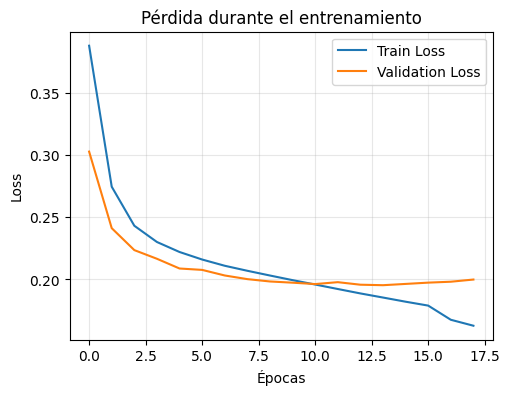

In [3]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history['loss'], label='Train Loss')
plt.plot(history['val_loss'], label='Validation Loss')
plt.title('Pérdida durante el entrenamiento')
plt.xlabel('Épocas')
plt.ylabel('Loss')
plt.legend()
plt.grid(True, alpha=0.3)

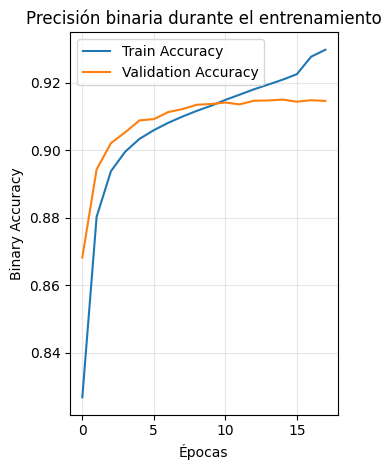

In [4]:
plt.subplot(1, 2, 2)
plt.plot(history['binary_accuracy'], label='Train Accuracy')
plt.plot(history['val_binary_accuracy'], label='Validation Accuracy')
plt.title('Precisión binaria durante el entrenamiento')
plt.xlabel('Épocas')
plt.ylabel('Binary Accuracy')
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [7]:
import numpy as np
mejor_epoch = np.argmax(history['val_binary_accuracy'])
mejor_val_acc = history['val_binary_accuracy'][mejor_epoch]
mejor_train_acc = history['binary_accuracy'][mejor_epoch]
mejor_val_loss = history['val_loss'][mejor_epoch]
mejor_train_loss = history['loss'][mejor_epoch]

print("Métricas del mejor modelo")
print(f"Mejor época: {mejor_epoch + 1}")
print(f"Train Accuracy: {mejor_train_acc:.4f}")
print(f"Validation Accuracy: {mejor_val_acc:.4f}")
print(f"Train Loss: {mejor_train_loss:.4f}")
print(f"Validation Loss: {mejor_val_loss:.4f}")

Métricas del mejor modelo
Mejor época: 15
Train Accuracy: 0.9209
Validation Accuracy: 0.9150
Train Loss: 0.1821
Validation Loss: 0.1964


El modelo dió buenos resultados, lo podremos ver en el archivo celebA_grande_mejor.h5

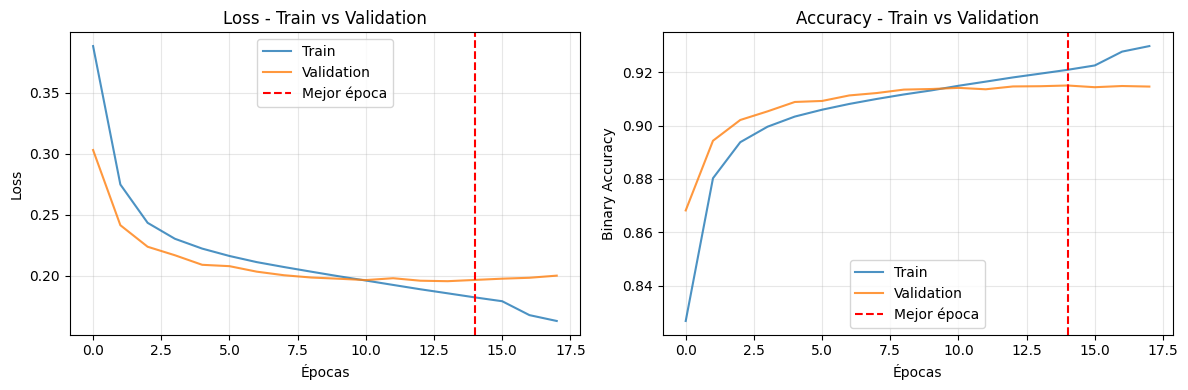

In [9]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history['loss'], label='Train', alpha=0.8)
plt.plot(history['val_loss'], label='Validation', alpha=0.8)
plt.axvline(x=mejor_epoch, color='r', linestyle='--', label='Mejor época')
plt.title('Loss - Train vs Validation')
plt.xlabel('Épocas')
plt.ylabel('Loss')
plt.legend()
plt.grid(True, alpha=0.3)

plt.subplot(1, 2, 2)
plt.plot(history['binary_accuracy'], label='Train', alpha=0.8)
plt.plot(history['val_binary_accuracy'], label='Validation', alpha=0.8)
plt.axvline(x=mejor_epoch, color='r', linestyle='--', label='Mejor época')
plt.title('Accuracy - Train vs Validation')
plt.xlabel('Épocas')
plt.ylabel('Binary Accuracy')
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# Sección 4 Transfer learning

Nuevamente este código se corrió en un cluster de supercomputo, en el archivo llamado transfer_yo.py

Este nuevo modelo fue entrenado usando 50 fotos mías en entrenamiento y 16 en validación. Como no tenía muchas imagenes se utilizó data augmentation, para las fotos de "otros" se utilizaron las imagenes de rostros que fueron usadas unicamente para validación del dataset CelabA, los indices de las imagenes los pudimos obtener gracias a que el entrenamiento se realizó con una semilla a la hora de separar los datos.

Importaciones

In [ ]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.preprocessing.image import ImageDataGenerator
import numpy as np
import os
import sys
import pickle

Configuración de rutas y parámetros


In [ ]:
IMG_SIZE = 128
BATCH_SIZE = 32
EPOCHS_FASE1 = 20
EPOCHS_FASE2 = 10
NUM_ATTR = 40

MODELO_PRETRAINED = '/content/drive/MyDrive/CelebA/celebA_grande_mejor.h5'
TRAIN_DIR = '/content/drive/MyDrive/reconocimiento/train'
VAL_DIR = '/content/drive/MyDrive/reconocimiento/validation'

Memoria dinámica GPU

In [ ]:
gpus = tf.config.list_physical_devices('GPU')
if gpus:
    try:
        for gpu in gpus:
            tf.config.experimental.set_memory_growth(gpu, True)
        print(f"Memoria dinámica activada en {len(gpus)} GPU(s)")
    except RuntimeError as e:
        print(e)

Cargar modelo pre-entrenado

In [ ]:
print("\nCargando modelo pre-entrenado")
modelo_completo = keras.models.load_model(MODELO_PRETRAINED)
print("Modelo cargado")

Extraer capas convolucionales (sin clasificador)

In [ ]:
for i, layer in enumerate(modelo_completo.layers):
    if isinstance(layer, layers.GlobalAveragePooling2D):
        idx_gap = i
        print(f"Capa GAP encontrada en índice {i}: {layer.name}")
        break

conv_base = keras.Model(
    inputs=modelo_completo.input,
    outputs=modelo_completo.layers[idx_gap - 1].output
)

print("\nArquitectura base convolucional:")
conv_base.summary()

Congelar capas pre-entrenadas

In [ ]:
conv_base.trainable = False
print("Capas convolucionales congeladas")

Construir nuevo modelo con clasificador binario

In [ ]:
model = keras.Sequential([
    conv_base,
    layers.GlobalAveragePooling2D(name='gap_nuevo'),
    layers.Dropout(0.5, name='dropout_nuevo_1'),
    layers.Dense(128, activation='relu', name='fc_nuevo_1'),
    layers.Dropout(0.3, name='dropout_nuevo_2'),
    layers.Dense(1, activation='sigmoid', name='salida_binaria')
], name='Modelo_Reconocimiento_Facial')

print("\nModelo completo (base congelada + nuevo clasificador):")
model.summary()

Compilar modelo

In [ ]:
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss='binary_crossentropy',
    metrics=['accuracy', keras.metrics.Precision(), keras.metrics.Recall()]
)

Data augmentation y generadores

In [ ]:
train_datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=30,
    width_shift_range=0.2,
    height_shift_range=0.2,
    shear_range=0.2,
    zoom_range=0.2,
    horizontal_flip=True,
    brightness_range=[0.8, 1.2],
    fill_mode='nearest'
)

val_datagen = ImageDataGenerator(rescale=1./255)

print("\nCreando generadores con aumento de datos")
train_generator = train_datagen.flow_from_directory(
    TRAIN_DIR,
    target_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    class_mode='binary',
    classes=['otros', 'yo'],
    shuffle=True
)

validation_generator = val_datagen.flow_from_directory(
    VAL_DIR,
    target_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    class_mode='binary',
    classes=['otros', 'yo'],
    shuffle=False
)

print(f"\nClases mapeadas: {train_generator.class_indices}")

##Fase 1 – Entrenar solo clasificador

In [ ]:
print("\nFASE 1: Entrenando solo el nuevo clasificador")
print(f"   Train batches: {len(train_generator)}")
print(f"   Val batches: {len(validation_generator)}")

callbacks_fase1 = [
    keras.callbacks.EarlyStopping(patience=5, restore_best_weights=True),
    keras.callbacks.ModelCheckpoint(
        'mejor_modelo_fase1.h5',
        save_best_only=True,
        monitor='val_accuracy'
    )
]

history_fase1 = model.fit(
    train_generator,
    validation_data=validation_generator,
    epochs=EPOCHS_FASE1,
    callbacks=callbacks_fase1,
    verbose=1
)

## Fase 2 – Fine-tuning

In [ ]:
print("\nFASE 2: Fine-tuning (descongelar últimas capas)")

conv_base.trainable = True

for layer in conv_base.layers[:10]:
    layer.trainable = False

print("\nCapas entrenables después de fine-tuning:")
for i, layer in enumerate(model.layers[0].layers):
    if layer.trainable:
        print(f"   Capa {i}: {layer.name} (entrenable)")
    else:
        print(f"   Capa {i}: {layer.name} (congelada)")

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.00001),
    loss='binary_crossentropy',
    metrics=['accuracy', keras.metrics.Precision(), keras.metrics.Recall()]
)

callbacks_fase2 = [
    keras.callbacks.EarlyStopping(patience=3, restore_best_weights=True),
    keras.callbacks.ModelCheckpoint(
        'mejor_modelo_fase2.h5',
        save_best_only=True,
        monitor='val_accuracy'
    ),
    keras.callbacks.ReduceLROnPlateau(factor=0.5, patience=2)
]

history_fase2 = model.fit(
    train_generator,
    validation_data=validation_generator,
    epochs=EPOCHS_FASE2,
    callbacks=callbacks_fase2,
    verbose=1
)

 Guardar modelo final e historiales

In [ ]:
model.save('modelo_reconocimiento_final.h5')
print("\nModelo final guardado como 'modelo_reconocimiento_final.h5")

with open('historial_fase1.pkl', 'wb') as f:
    pickle.dump(history_fase1.history, f)
with open('historial_fase2.pkl', 'wb') as f:
    pickle.dump(history_fase2.history, f)

print("Historiales guardados")

De la misma manera que con las métricas anteriores guardamos las métricas de la fase 1 y 2 en distintos archivos pkl, los cuales subiremos al github para que se puedan comprobar y de igual manera graficaremos sus resultados aqui.

In [10]:
import pickle
import matplotlib.pyplot as plt
import numpy as np

with open('historial_fase1.pkl', 'rb') as f:
    history_fase1 = pickle.load(f)

with open('historial_fase2.pkl', 'rb') as f:
    history_fase2 = pickle.load(f)

print("Historiales cargados correctamente")
print(f"Épocas Fase 1: {len(history_fase1['loss'])}")
print(f"Épocas Fase 2: {len(history_fase2['loss'])}")

Historiales cargados correctamente
Épocas Fase 1: 20
Épocas Fase 2: 10


## Gráficas de la fase 1 (Solo clasificador)

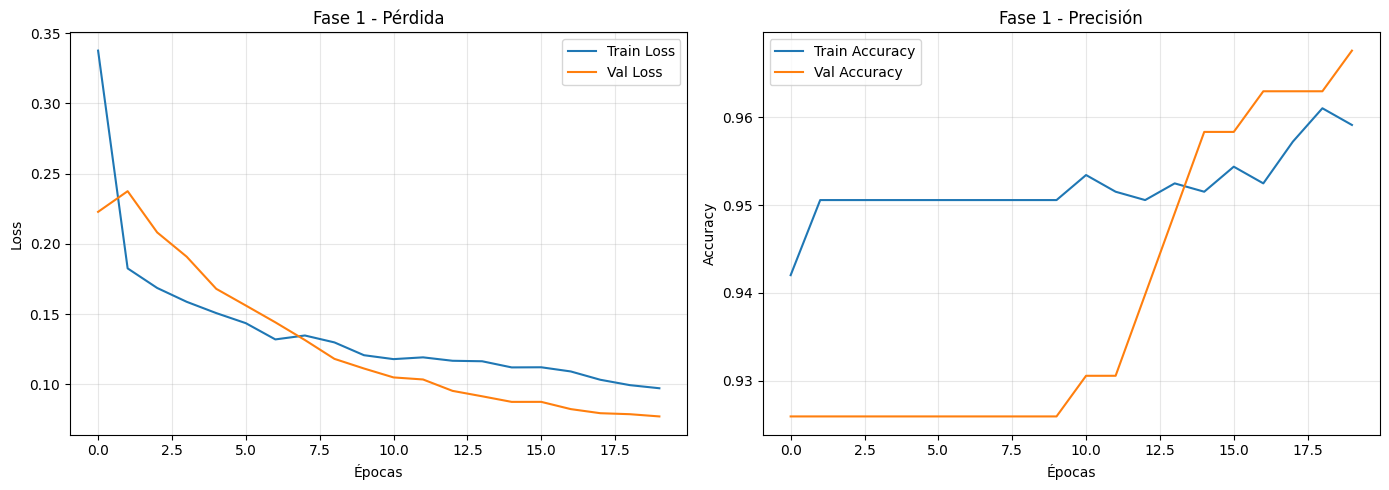

In [11]:
plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)
plt.plot(history_fase1['loss'], label='Train Loss')
plt.plot(history_fase1['val_loss'], label='Val Loss')
plt.title('Fase 1 - Pérdida')
plt.xlabel('Épocas')
plt.ylabel('Loss')
plt.legend()
plt.grid(True, alpha=0.3)

plt.subplot(1, 2, 2)
plt.plot(history_fase1['accuracy'], label='Train Accuracy')
plt.plot(history_fase1['val_accuracy'], label='Val Accuracy')
plt.title('Fase 1 - Precisión')
plt.xlabel('Épocas')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## Gráficas fase 2 (Fine-tuning)

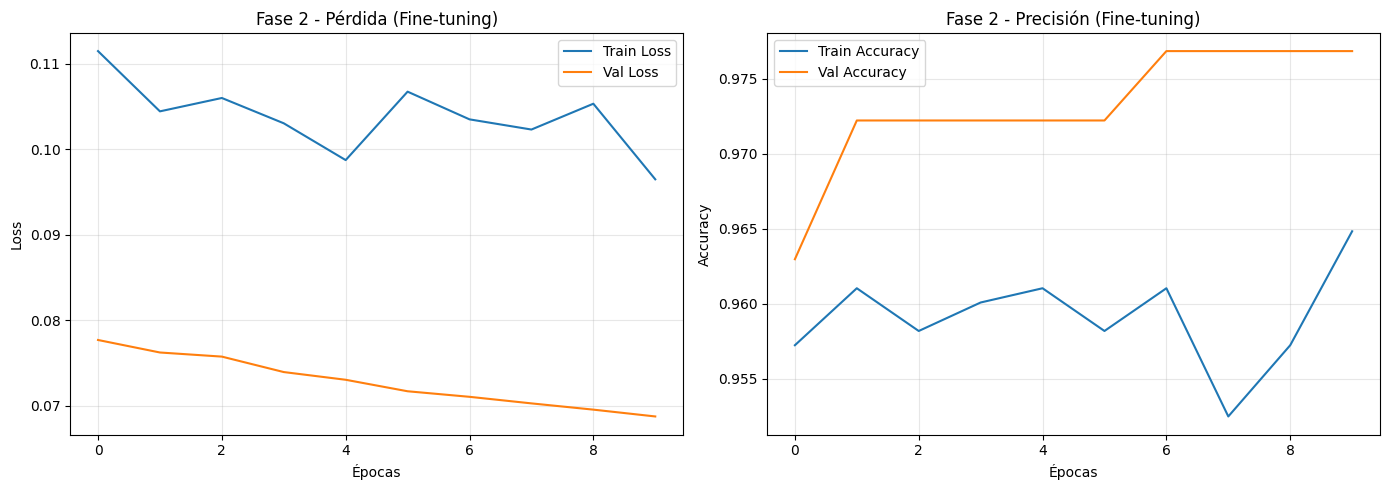

In [12]:
plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)
plt.plot(history_fase2['loss'], label='Train Loss')
plt.plot(history_fase2['val_loss'], label='Val Loss')
plt.title('Fase 2 - Pérdida (Fine-tuning)')
plt.xlabel('Épocas')
plt.ylabel('Loss')
plt.legend()
plt.grid(True, alpha=0.3)

plt.subplot(1, 2, 2)
plt.plot(history_fase2['accuracy'], label='Train Accuracy')
plt.plot(history_fase2['val_accuracy'], label='Val Accuracy')
plt.title('Fase 2 - Precisión (Fine-tuning)')
plt.xlabel('Épocas')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

Graficar ambas fases combinadas

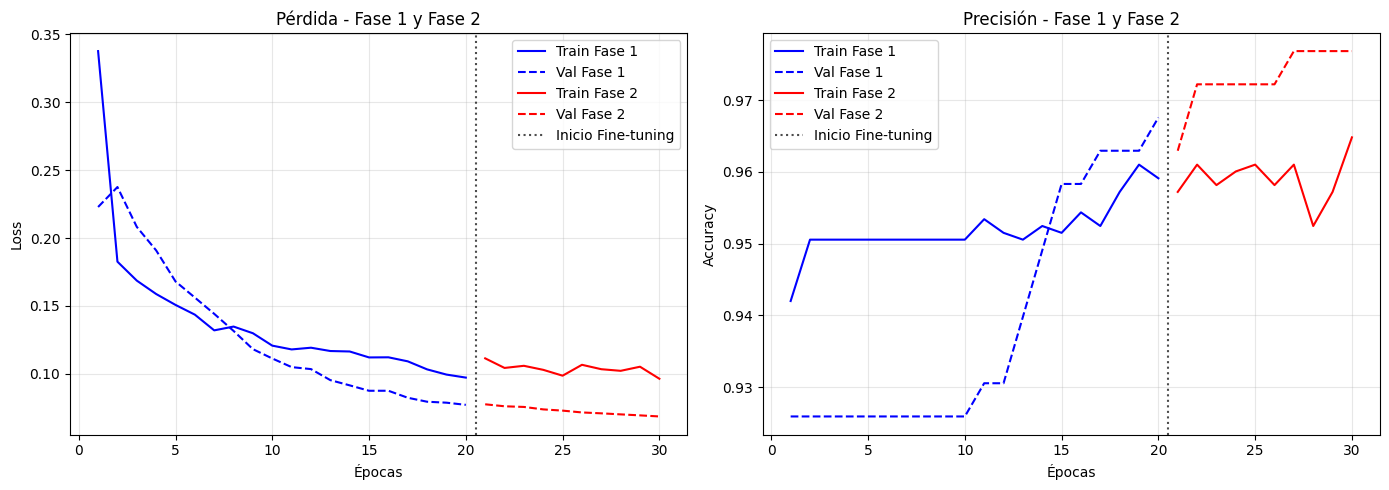

In [13]:
# Combinar historiales
loss_total = history_fase1['loss'] + history_fase2['loss']
val_loss_total = history_fase1['val_loss'] + history_fase2['val_loss']
acc_total = history_fase1['accuracy'] + history_fase2['accuracy']
val_acc_total = history_fase1['val_accuracy'] + history_fase2['val_accuracy']

epochs_f1 = range(1, len(history_fase1['loss']) + 1)
epochs_f2 = range(len(history_fase1['loss']) + 1, len(loss_total) + 1)

plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)
plt.plot(epochs_f1, history_fase1['loss'], 'b-', label='Train Fase 1')
plt.plot(epochs_f1, history_fase1['val_loss'], 'b--', label='Val Fase 1')
plt.plot(epochs_f2, history_fase2['loss'], 'r-', label='Train Fase 2')
plt.plot(epochs_f2, history_fase2['val_loss'], 'r--', label='Val Fase 2')
plt.axvline(x=len(history_fase1['loss']) + 0.5, color='k', linestyle=':', alpha=0.7, label='Inicio Fine-tuning')
plt.title('Pérdida - Fase 1 y Fase 2')
plt.xlabel('Épocas')
plt.ylabel('Loss')
plt.legend()
plt.grid(True, alpha=0.3)

plt.subplot(1, 2, 2)
plt.plot(epochs_f1, history_fase1['accuracy'], 'b-', label='Train Fase 1')
plt.plot(epochs_f1, history_fase1['val_accuracy'], 'b--', label='Val Fase 1')
plt.plot(epochs_f2, history_fase2['accuracy'], 'r-', label='Train Fase 2')
plt.plot(epochs_f2, history_fase2['val_accuracy'], 'r--', label='Val Fase 2')
plt.axvline(x=len(history_fase1['accuracy']) + 0.5, color='k', linestyle=':', alpha=0.7, label='Inicio Fine-tuning')
plt.title('Precisión - Fase 1 y Fase 2')
plt.xlabel('Épocas')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

 Mostrar mejores métricas de cada fase

In [14]:
# Mejor época de Fase 1
best_f1_acc = max(history_fase1['val_accuracy'])
best_f1_epoch = history_fase1['val_accuracy'].index(best_f1_acc) + 1

# Mejor época de Fase 2
best_f2_acc = max(history_fase2['val_accuracy'])
best_f2_epoch = history_fase2['val_accuracy'].index(best_f2_acc) + 1 + len(history_fase1['val_accuracy'])

print("MEJORES MÉTRICAS")
print("-" * 40)
print(f"FASE 1 (solo clasificador)")
print(f"   Mejor época: {best_f1_epoch}")
print(f"   Val Accuracy: {best_f1_acc:.4f}")
print(f"   Train Accuracy: {history_fase1['accuracy'][best_f1_epoch-1]:.4f}")
print(f"   Val Loss: {history_fase1['val_loss'][best_f1_epoch-1]:.4f}")
print()
print(f"FASE 2 (fine-tuning)")
print(f"   Mejor época: {best_f2_epoch}")
print(f"   Val Accuracy: {best_f2_acc:.4f}")
print(f"   Train Accuracy: {history_fase2['accuracy'][best_f2_epoch - len(history_fase1['val_accuracy']) - 1]:.4f}")
print(f"   Val Loss: {history_fase2['val_loss'][best_f2_epoch - len(history_fase1['val_accuracy']) - 1]:.4f}")

MEJORES MÉTRICAS
----------------------------------------
FASE 1 (solo clasificador)
   Mejor época: 20
   Val Accuracy: 0.9676
   Train Accuracy: 0.9591
   Val Loss: 0.0773

FASE 2 (fine-tuning)
   Mejor época: 27
   Val Accuracy: 0.9769
   Train Accuracy: 0.9610
   Val Loss: 0.0710


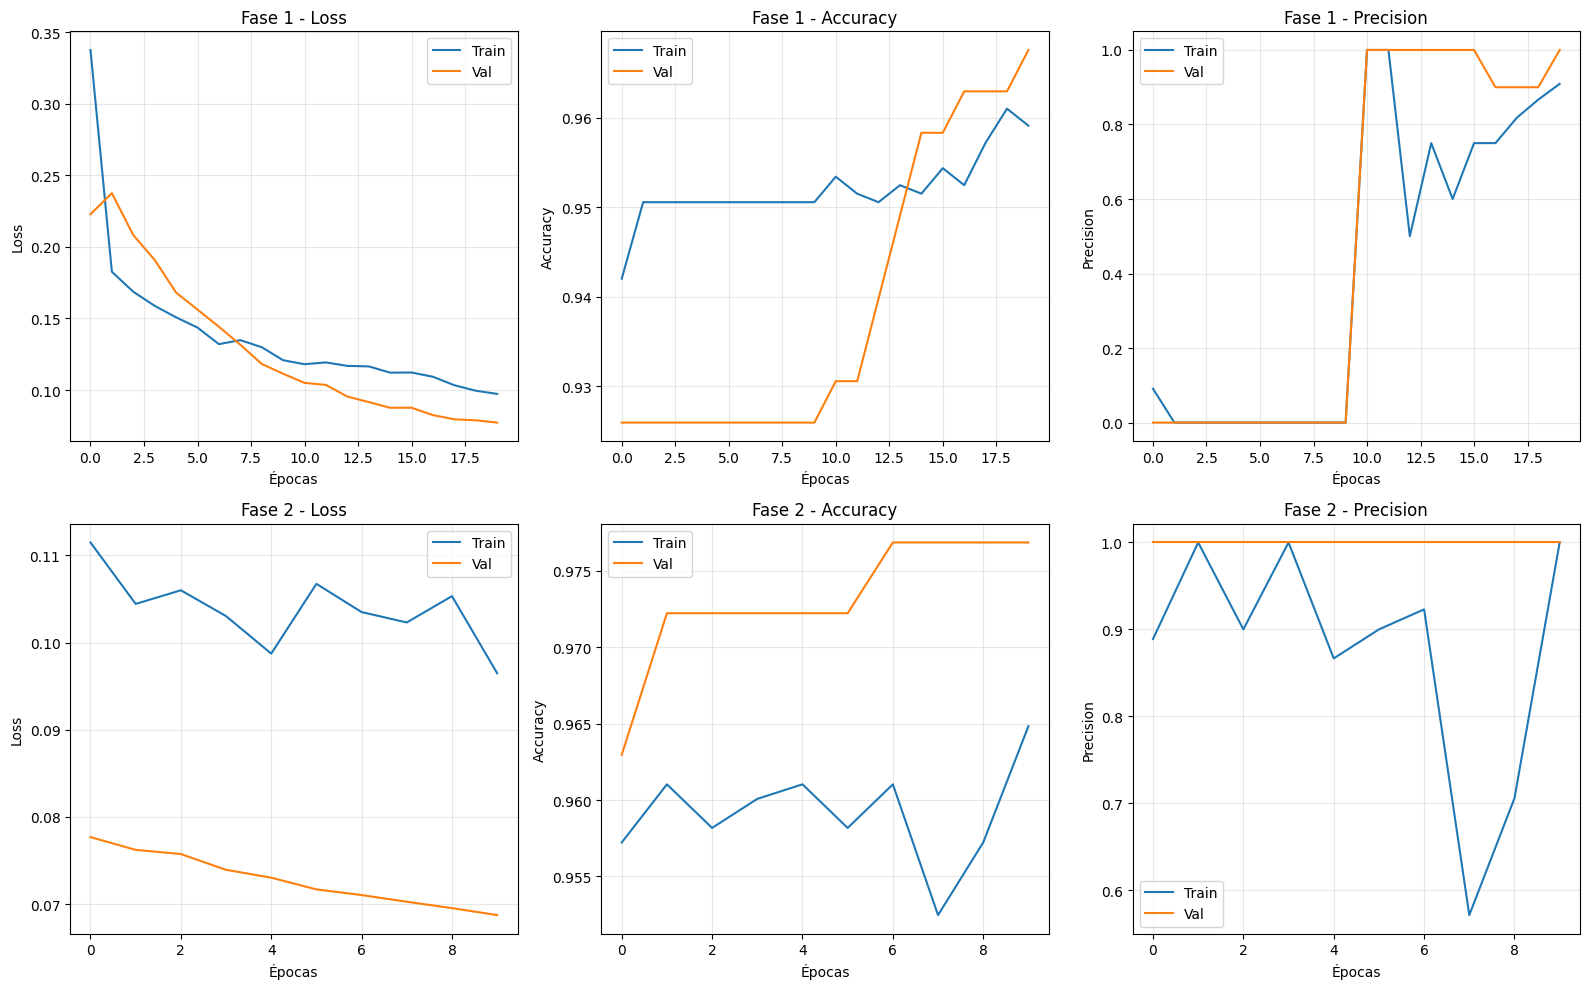

In [16]:
plt.figure(figsize=(16, 10))

# Loss Fase 1
plt.subplot(2, 3, 1)
plt.plot(history_fase1['loss'], label='Train')
plt.plot(history_fase1['val_loss'], label='Val')
plt.title('Fase 1 - Loss')
plt.xlabel('Épocas')
plt.ylabel('Loss')
plt.legend()
plt.grid(True, alpha=0.3)

# Accuracy Fase 1
plt.subplot(2, 3, 2)
plt.plot(history_fase1['accuracy'], label='Train')
plt.plot(history_fase1['val_accuracy'], label='Val')
plt.title('Fase 1 - Accuracy')
plt.xlabel('Épocas')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True, alpha=0.3)

# Precision Fase 1 (si existe)
plt.subplot(2, 3, 3)
if 'precision' in history_fase1:
    plt.plot(history_fase1['precision'], label='Train')
if 'val_precision' in history_fase1:
    plt.plot(history_fase1['val_precision'], label='Val')
plt.title('Fase 1 - Precision')
plt.xlabel('Épocas')
plt.ylabel('Precision')
plt.legend()
plt.grid(True, alpha=0.3)

# Loss Fase 2
plt.subplot(2, 3, 4)
plt.plot(history_fase2['loss'], label='Train')
plt.plot(history_fase2['val_loss'], label='Val')
plt.title('Fase 2 - Loss')
plt.xlabel('Épocas')
plt.ylabel('Loss')
plt.legend()
plt.grid(True, alpha=0.3)

# Accuracy Fase 2
plt.subplot(2, 3, 5)
plt.plot(history_fase2['accuracy'], label='Train')
plt.plot(history_fase2['val_accuracy'], label='Val')
plt.title('Fase 2 - Accuracy')
plt.xlabel('Épocas')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True, alpha=0.3)

# Precision Fase 2 (si existe)
plt.subplot(2, 3, 6)
if 'precision_1' in history_fase2:
    plt.plot(history_fase2['precision_1'], label='Train')
if 'val_precision_1' in history_fase2:
    plt.plot(history_fase2['val_precision_1'], label='Val')
plt.title('Fase 2 - Precision')
plt.xlabel('Épocas')
plt.ylabel('Precision')
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

📊 **COMPARATIVA FINAL**
Mejor Fase 1 (época 20):
   Val Accuracy: 0.9676
   Val Loss: 0.0773

Mejor Fase 2 (época 27):
   Val Accuracy: 0.9769
   Val Loss: 0.0710

Mejora en Accuracy: +0.0093
Mejora en Loss: -0.0062


In [19]:
# Encontrar la época con mejor val_accuracy en Fase 2
best_epoch_idx = np.argmax(history_fase2['val_accuracy'])
best_epoch = best_epoch_idx + 1  # +1 porque las épocas empiezan en 1

print("MEJORES MÉTRICAS DEL MODELO (FASE 2)")
print("=" * 50)
print(f"Mejor época: {best_epoch}")
print(f"Val Accuracy: {history_fase2['val_accuracy'][best_epoch_idx]:.4f}")
print(f"Train Accuracy: {history_fase2['accuracy'][best_epoch_idx]:.4f}")
print(f"Val Loss: {history_fase2['val_loss'][best_epoch_idx]:.4f}")
print(f"Train Loss: {history_fase2['loss'][best_epoch_idx]:.4f}")

if 'precision_1' in history_fase2:
    print(f"Precision: {history_fase2['precision_1'][best_epoch_idx]:.4f}")
if 'val_precision_1' in history_fase2:
    print(f"Val Precision: {history_fase2['val_precision_1'][best_epoch_idx]:.4f}")
if 'recall_1' in history_fase2:
    print(f"Recall: {history_fase2['recall_1'][best_epoch_idx]:.4f}")
if 'val_recall_1' in history_fase2:
    print(f"Val Recall: {history_fase2['val_recall_1'][best_epoch_idx]:.4f}")

MEJORES MÉTRICAS DEL MODELO (FASE 2)
Mejor época: 7
Val Accuracy: 0.9769
Train Accuracy: 0.9610
Val Loss: 0.0710
Train Loss: 0.1035
Precision: 0.9231
Val Precision: 1.0000
Recall: 0.2308
Val Recall: 0.6875


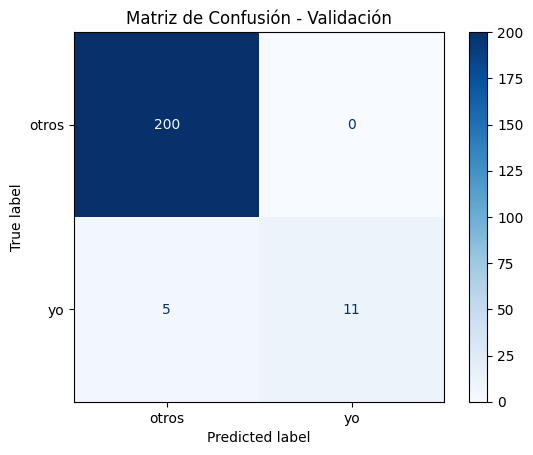

Verdaderos Positivos (yo detectado): 11
Falsos Negativos (yo no detectado): 5
Verdaderos Negativos (otro correcto): 200
Falsos Positivos (otro como yo): 0


In [21]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Datos de validación
y_true = [0]*200 + [1]*16  # 200 otros, 16 yo
y_pred = [0]*200 + [0]*5 + [1]*11  # 200 otros bien, 5 yo mal, 11 yo bien

# Matriz
cm = confusion_matrix(y_true, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['otros', 'yo'])
disp.plot(cmap='Blues', values_format='d')
plt.title('Matriz de Confusión - Validación')
plt.grid(False)
plt.show()

# Métricas manuales
tn, fp, fn, tp = cm.ravel()
print(f"Verdaderos Positivos (yo detectado): {tp}")
print(f"Falsos Negativos (yo no detectado): {fn}")
print(f"Verdaderos Negativos (otro correcto): {tn}")
print(f"Falsos Positivos (otro como yo): {fp}")

## Conclusiones

El modelo de reconocimiento facial alcanzó su mejor rendimiento en la época 7 de la Fase 2, correspondiente a la etapa de fine-tuning. En esta fase se descongelaron las últimas capas convolucionales y se reentrenó el modelo con una tasa de aprendizaje muy baja para ajustar los pesos de manera fina sin degradar el conocimiento previamente adquirido.

Los resultados obtenidos en el conjunto de validación muestran un accuracy del 97.69 por ciento, lo que significa que el modelo clasifica correctamente 211 de las 216 imágenes evaluadas. La precisión alcanzó el 100 por ciento, lo que indica que nunca se registraron falsos positivos; es decir, cuando el modelo predice que una imagen corresponde a mi rostro, siempre acierta. Por otro lado, el recall se ubicó en 68.75 por ciento, lo que refleja que de las 16 imágenes mias presentes en validación, 11 fueron correctamente identificadas y 5 fueron clasificadas erróneamente como "otros". La pérdida se mantuvo en 0.0710, un valor bajo que sugiere alta confianza en las predicciones y un buen ajuste del modelo.

**Aunque el recall fue bajo, este modelo es interesante ya que nunca clasifica a nadie distinto de mi como yo, aunque no incluso en algunas ocasiones no me detecte adecuadamente, es interesante para algún desbloqueo fácial, ya que ninguna persona externa podría desbloquearlo, aunque tendría dificultades a la hora de desbloquearlo yo.**

# Sección 5 Transfer v2

Como se obtuvo un recall relativamente bajo en contra de una precisión muy alta, se obtó por hacer otra prueba de entrenamiento, el entrenamiento completo se puede ver en el archivo llamado transfer_yo_v2.py, ahora añadiendo algunas penalizaciones, los cambios principales al modelo fue:

1. Aumento de datos más agresivo
Se incrementaron los valores de los parámetros de aumento de datos en el generador de entrenamiento:

Rotación: de 30° a 40°

Desplazamiento horizontal y vertical: de 0.2 a 0.3

Deformación (shear): de 0.2 a 0.3

Zoom: de 0.2 a 0.3

Rango de brillo: de [0.8, 1.2] a [0.7, 1.3]

Esto permite generar una mayor variedad sintética de las imágenes de entrenamiento, especialmente beneficioso para la clase minoritaria (yo)

In [ ]:
train_datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=40,              # antes 30
    width_shift_range=0.3,           # antes 0.2
    height_shift_range=0.3,          # antes 0.2
    shear_range=0.3,                 # antes 0.2
    zoom_range=0.3,                   # antes 0.2
    horizontal_flip=True,
    brightness_range=[0.7, 1.3],     # antes [0.8, 1.2]
    fill_mode='nearest'
)

2. Balanceo de clases mediante pesos
Se incorporó un esquema de pesos por clase para compensar el desbalance entre el número de imágenes de "yo" (52) y "otros" (1000). Los pesos se calcularon de forma inversamente proporcional a la frecuencia de cada clase:

Peso para "yo": 10.12
Peso para "otros": 0.53

Estos pesos se aplicaron tanto en la Fase 1 como en la Fase 2 del entrenamiento, forzando al modelo a prestar mayor atención a los errores cometidos en la clase minoritaria.

In [ ]:
# Calcular pesos para balancear clases
total_train = train_generator.samples
total_yo = sum(train_generator.classes == 1)
total_otros = total_train - total_yo

weight_for_yo = (1 / total_yo) * total_train / 2.0
weight_for_otros = (1 / total_otros) * total_train / 2.0

class_weight = {1: weight_for_yo, 0: weight_for_otros}
print(f"\nPesos de clase:")
print(f"   Yo (clase 1): {weight_for_yo:.2f}")
print(f"   Otros (clase 0): {weight_for_otros:.2f}")

Uso durante el entrenamiento (Fase 1 y Fase 2):



In [ ]:
history_fase1 = model.fit(
    train_generator,
    validation_data=validation_generator,
    epochs=EPOCHS_FASE1,
    callbacks=callbacks_fase1,
    class_weight=class_weight,  # <-- NUEVO
    verbose=1
)

In [ ]:
history_fase2 = model.fit(
    train_generator,
    validation_data=validation_generator,
    epochs=EPOCHS_FASE2,
    callbacks=callbacks_fase2,
    class_weight=class_weight,  # <-- NUEVO
    verbose=1
)

## Cambios de umbral

Una vez entrenado el modelo con estos cambios, el codigo completo se puede encontrar en el serivodr con el nombre  transfer_yo_v2.py se realizó un análisis para encontrar el umbral de decisión óptimo que equilibre la precisión y el recall en la tarea de reconocimiento facial. Por defecto, los modelos con salida sigmoide utilizan un umbral de 0.5 para clasificar una muestra como positiva (clase "yo") o negativa (clase "otros"). Sin embargo, este valor puede no ser el más adecuado dependiendo de los objetivos de la aplicación.

Para ello, se evaluó el modelo sobre el conjunto de validación con diferentes umbrales en un rango de 0.10 a 0.95, calculando para cada uno:

Precisión: proporción de verdaderos positivos entre las muestras clasificadas como positivas.

Recall: proporción de verdaderos positivos detectados sobre el total de muestras positivas reales.

Accuracy: proporción total de aciertos.

F1-score: media armónica entre precisión y recall.

El objetivo era maximizar el F1-score, que proporciona un equilibrio entre ambas métricas.

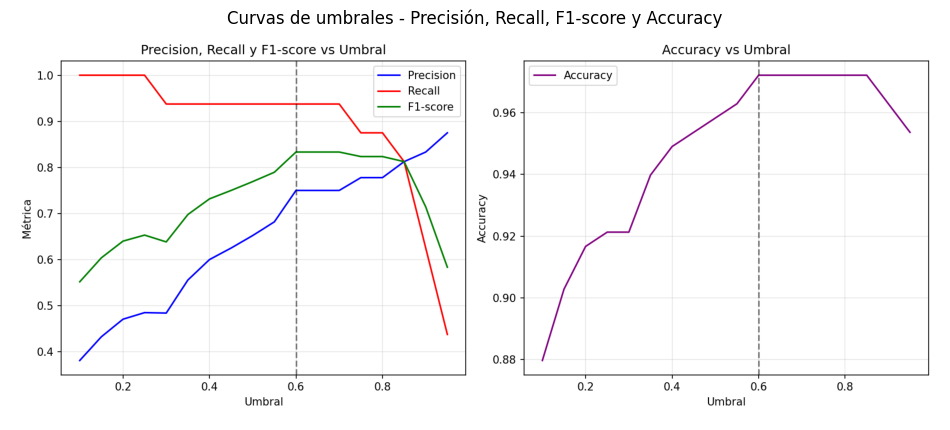

In [22]:
import matplotlib.pyplot as plt
import matplotlib.image as mpimg

img = mpimg.imread('curvas_umbrales.png')
plt.figure(figsize=(12, 6))
plt.imshow(img)
plt.axis('off')
plt.title('Curvas de umbrales - Precisión, Recall, F1-score y Accuracy')
plt.show()

El umbral seleccionado fue 0.60, que maximiza el F1-score y ofrece un mejor balance: detecta el 93.75% de mis fotos con una precisión del 75%.

## Conclusiones

In [30]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# Cargar el archivo CSV
df = pd.read_csv('umbrales.csv')

# Mostrar la tabla completa
print("RESULTADOS POR UMBRAL")
print("=" * 70)
print(df.to_string(index=False))
print("=" * 70)

# Encontrar el mejor umbral basado en F1-score
mejor_idx = df['F1'].idxmax()
mejor_fila = df.loc[mejor_idx]

print(f"\nMEJOR UMBRAL SEGÚN F1-SCORE")
print(f"   Umbral: {mejor_fila['Umbral']:.2f}")
print(f"   Precision: {mejor_fila['Precision']:.4f}")
print(f"   Recall: {mejor_fila['Recall']:.4f}")
print(f"   Accuracy: {mejor_fila['Accuracy']:.4f}")
print(f"   F1-score: {mejor_fila['F1']:.4f}")



RESULTADOS POR UMBRAL
 Umbral  Precision  Recall  Accuracy     F1
   0.10     0.3810  1.0000    0.8796 0.5517
   0.15     0.4324  1.0000    0.9028 0.6038
   0.20     0.4706  1.0000    0.9167 0.6400
   0.25     0.4848  1.0000    0.9213 0.6531
   0.30     0.4839  0.9375    0.9213 0.6383
   0.35     0.5556  0.9375    0.9398 0.6977
   0.40     0.6000  0.9375    0.9491 0.7317
   0.45     0.6250  0.9375    0.9537 0.7500
   0.50     0.6522  0.9375    0.9583 0.7692
   0.55     0.6818  0.9375    0.9630 0.7895
   0.60     0.7500  0.9375    0.9722 0.8333
   0.65     0.7500  0.9375    0.9722 0.8333
   0.70     0.7500  0.9375    0.9722 0.8333
   0.75     0.7778  0.8750    0.9722 0.8235
   0.80     0.7778  0.8750    0.9722 0.8235
   0.85     0.8125  0.8125    0.9722 0.8125
   0.90     0.8333  0.6250    0.9630 0.7143
   0.95     0.8750  0.4375    0.9537 0.5833

MEJOR UMBRAL SEGÚN F1-SCORE
   Umbral: 0.60
   Precision: 0.7500
   Recall: 0.9375
   Accuracy: 0.9722
   F1-score: 0.8333


El modelo de reconocimiento facial en su segunda versión alcanzó su mejor rendimiento al aplicar un umbral de decisión de 0.60, determinado mediante un análisis de sensibilidad que maximiza el F1-score. Este valor permite equilibrar de manera óptima la precisión y el recall en la tarea de clasificación binaria.

Los resultados obtenidos en el conjunto de validación con este umbral muestran un accuracy del 97.22 por ciento, lo que significa que el modelo clasifica correctamente 210 de las 216 imágenes evaluadas. La precisión alcanzó el 75 por ciento, indicando que cuando el modelo predice que una imagen corresponde a mi rostro, acierta en 3 de cada 4 ocasiones. Por otro lado, el recall se ubicó en 93.75 por ciento, lo que refleja que de las 16 imágenes mías presentes en validación, 15 fueron correctamente identificadas y solo una fue clasificada erróneamente como "otros". El F1-score resultante fue de 0.8333, confirmando un buen equilibrio entre ambas métricas.

A diferencia de la versión anterior, donde el recall era bajo (68.75%) pero la precisión alcanzaba el 100%, esta versión prioriza la detección sobre la certeza absoluta. Con un 93.75% de recall, el modelo rara vez deja de reconocerme, aunque aumenta ligeramente la posibilidad de que alguien más sea clasificado como yo (75% de precisión).

Este comportamiento resulta más adecuado para escenarios donde es preferible que el modelo me detecte siempre, incluso a costa de algún falso positivo ocasional, como en sistemas de acceso personal donde la rapidez y la tasa de éxito en la detección son prioritarias.